# Homework №3


## Effective Flow Matching Training (10 pt)


In this homework, you are asked to:

1) Implement a pixel-space flow matching model ([JiT](https://arxiv.org/abs/2511.13720)architecture) **(6 pt)**

2) Adapt it to the latent diffusion model (i.e., run it in VAE space) **(1 pt)**

3) Implement [REPA](https://openreview.net/forum?id=DJSZGGZYVi) to enforce diffusion to learn internal features faster **(3 pt)**



### Install if required

In [ ]:
! wget https://storage.yandexcloud.net/yandex-research/visual-genai/stanford_cars.tar
! wget https://storage.yandexcloud.net/yandex-research/visual-genai/stanford_cars_flat.tar
! wget https://storage.yandexcloud.net/yandex-research/visual-genai/latents_stanford_cars.pt
! tar -xf stanford_cars.tar
! tar -xf stanford_cars_flat.tar

In [ ]:
! pip install torch_fidelity

### Import libraries

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
import math
import sys
import time
import torch_fidelity
import matplotlib.pyplot as plt
from IPython.display import clear_output
import os
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, datasets
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from transformers import AutoModel

c:\Users\user\Desktop\code\VisualGenAI\assignments\hw3_flow_matching\.venv-hw3-py313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Flow matching implementation (6 pt)

Implement flow matching training and sampling for the pixel-space diffusion transformer, [JiT](https://arxiv.org/abs/2511.13720). 

**Important:** do not consider JiT as a reference for FM implementation. They use different notation, which may lead to exhausting debugging.

---

In this task, you need to implement the following FM setup:

**Forward process:** $(1-t) x + t \epsilon$

**v-loss:** $\lVert v_\theta - v \rVert^2_2$

Pay attention to the correct model output parameterization in the pixel space. (Manifold assumption)

In [2]:
from model_jit import JiT_models
from torch.distributions import (
    Normal,
    TransformedDistribution,
    SigmoidTransform,
)


class Denoiser(nn.Module):
    def __init__(
        self,
        model="JiT-S/16",
        img_size=256,
        in_channels=3,
        class_num=196,
        label_drop_prob=0.1,
        P_mean=0.8,
        P_std=0.8,
        t_eps=5e-2,
    ):
        super().__init__()
        self.net = JiT_models[model](
            input_size=img_size,
            in_channels=in_channels,
            num_classes=class_num,
        )
        self.in_channels = in_channels
        self.img_size = img_size
        self.num_classes = class_num

        self.label_drop_prob = label_drop_prob
        self.P_mean = P_mean
        self.P_std = P_std
        self.t_eps = (
            t_eps  # use to avoid zero-division when reparametrize the model prediction
        )

    def drop_labels(self, labels):
        """
        Implement label dropping during training for CFG (use self.label_drop_prob)
        """
        # <YOUR CODE>
        mask = torch.rand(labels.shape, device=labels.device) < self.label_drop_prob
        return torch.where(mask, self.num_classes, labels)

    def sample_t(self, n: int, device=None):
        """
        Implement timestep sampling distribution.

        Use shifted logit normal with parameters self.P_std and self.P_mean
        """

        normal_samples = torch.randn(n, device=device) * self.P_std + self.P_mean
        return normal_samples.sigmoid()

    def forward(
        self, x, labels, pixel_image=None, dino_encoder=None, repa=None, extractor=None
    ):
        """
        Implement flow matching loss calculation.
        1) Drop labels for CFG
        2) Apply forward process to x
        3) Select the proper prediction type for the model
        4) Compute v-loss
        5) Add the REPA loss (Advice: implement it when you approach the corresponding cell)

        Args:
            x: clean images (or latents)
            labels: class labels
            ----------
            REPA args
            ----------
            pixel_image: use it as a DINO input for REPA. Do not forget preprocess is using dino_preprocess_raw_image()
            dino_encoder: DINO encoder for REPA
            repa: REPA class object that implements the feature projector and REPA loss
            extractor: Extracts intermediate diffusion activations. You can implement this another way - up to you.
        """
        # <YOUR CODE>
        labels = self.drop_labels(labels)
        batch_size = x.shape[0]
        sampled_t = self.sample_t(batch_size, device=labels.device).reshape(-1, 1, 1, 1)
        noize = torch.randn_like(x)
        noized_images = (1 - sampled_t) * x + sampled_t * noize

        predicted_images = self.net(noized_images, sampled_t.flatten(), labels)
        time_weights = sampled_t.flatten().clamp_min(self.t_eps).pow(-2)
        image_errors = ((x.float() - predicted_images.float()) ** 2).mean(dim=(1, 2, 3))
        loss = (time_weights * image_errors).mean()
        # REPA loss
        if dino_encoder is not None:
            # <YOUR CODE>
            dino_features = dino_preprocess_raw_image(pixel_image)
            with torch.no_grad():
                dino_features = dino_encoder(dino_features).last_hidden_state
            dm_features = extractor.get_layer_activation()
            repa_loss = repa(dm_features, dino_features)
            loss+=repa_loss

        return loss


@torch.no_grad()
def generate(model, labels, steps=25, cfg_scale=4.0, vae=None):
    """
    Implement a flow matching
    tion process. You are free to use any solver. Euler is okay.
    You can also use any timestep scheduler from the previous HW.

    Hints:
        1) Do not forget about CFG. We already set the okay default cfg_scale but you free to play with it
        2) Consider torch.autocast to float16 for faster sampling
        3) (For the latent model) Do not forget to denormalize latents before decoding
    """
    # <YOUR CODE>
    model_param = next(model.parameters())
    device = model_param.device
    labels = labels.to(device)
    timestamps = torch.linspace(1, 0, steps, device=device)
    batch_size = labels.shape[0]
    noize = torch.randn(
        batch_size, model.in_channels, model.img_size, model.img_size,
        device=device, dtype=model_param.dtype,
    )
    if vae is not None:
        # <YOUR CODE>
        pass

    cur_images = noize
    cfg_labels = torch.cat([torch.full_like(labels, model.num_classes), labels])
    for i in range(len(timestamps) - 1):
        delta_t = timestamps[i] - timestamps[i + 1]
        cfg_images = cur_images.repeat(2, 1, 1, 1)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=device.type == "cuda"):
            predicted_img = model.net(
                cfg_images,
                timestamps[i].repeat(2 * batch_size),
                cfg_labels,
            )
        velocity = (predicted_img.float() - cfg_images) / timestamps[i].clamp_min(model.t_eps)
        cfg_conditioned_velocity = velocity[:batch_size] + cfg_scale * (
            velocity[batch_size:] - velocity[:batch_size]
        )
        cur_images = cur_images + cfg_conditioned_velocity * delta_t

    if vae:
        cur_images /= vae.config.scaling_factor
        cur_images = vae.decode(cur_images).sample
    return cur_images

In [3]:
# Training and performance settings (Windows / RTX 5070 Ti)

device = torch.device("cuda")
lr = 5e-4
batch_size = 32
model_name = "JiT-S/16"  # Try JiT-B/16 after measuring VRAM usage.
amp_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
enable_compile = True
compile_mode = "reduce-overhead"  # "default" is also available for comparison.
num_workers = min(4, max(1, (os.cpu_count() or 2) // 2))

# PyTorch 2.9.1 Inductor reads the legacy TF32 flags internally.
# Use only this API family; restart the kernel after changing TF32 settings.
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# PyTorch 2.9.1 static launcher can overflow a CUDA stream handle on Windows.
if sys.platform == "win32":
    import torch._inductor.config as inductor_config
    inductor_config.use_static_cuda_launcher = False


### Create dataset and dataloader

We train our model on the [Stanford Cars](https://huggingface.co/datasets/tanganke/stanford_cars) dataset. It contains 16183 images of 196 classes.


**Dataset class returns a clean image, precomputed VAE latent and label.**

Note that you do not need to encode images during latent diffusion training with the VAE encoder.

![dataset](https://storage.yandexcloud.net/yandex-research/visual-genai/stanford_cars_demo.png)

In [4]:
from data_utils import ImageWithLatentDataset, make_image_transform, configure_worker

transform = make_image_transform()
dataset_train = ImageWithLatentDataset(
    image_folder="stanford_cars",
    latents_file="latents_stanford_cars.pt",
    transform=transform,
)
print(f"Dataset size: {len(dataset_train)}")

loader_options = {}
if num_workers > 0:
    loader_options.update(
        persistent_workers=True,
        prefetch_factor=2,
        worker_init_fn=configure_worker,
        multiprocessing_context="spawn",
    )

data_loader_train = DataLoader(
    dataset_train,
    batch_size=batch_size,
    num_workers=num_workers,
    pin_memory=device.type == "cuda",
    drop_last=True,
    shuffle=True,
    **loader_options,
)


Dataset size: 16183


### Evaluation function

You can use it as is. No coding here

In [5]:
@torch.no_grad()
def evaluate(
    model, cfg_scale=3.0, batch_size=49, num_images=196, save_folder="samples", vae=None
):
    assert num_images % batch_size == 0
    num_steps = num_images // batch_size

    print("Saving images to:", save_folder)
    if not os.path.exists(save_folder):
        os.makedirs(save_folder)

    class_num = model.num_classes
    assert num_images % class_num == 0, "Number of images per class must be the same"
    class_label = np.arange(0, class_num).repeat(num_images // class_num)

    for i in range(num_steps):
        start_idx = batch_size * i
        end_idx = start_idx + batch_size
        labels_gen = class_label[start_idx:end_idx]
        labels_gen = torch.Tensor(labels_gen).long().cuda()

        sampled_images = generate(model, labels_gen, vae=vae, cfg_scale=cfg_scale)

        # denormalize images
        sampled_images = (sampled_images + 1) / 2
        sampled_images = sampled_images.clamp(0, 1)
        sampled_images = sampled_images.detach().cpu()

        # distributed save images
        for b_id in range(sampled_images.size(0)):
            img_id = i * sampled_images.size(0) + b_id

            arr = (sampled_images[b_id].permute(1, 2, 0).float().numpy() * 255).astype(
                np.uint8
            )
            Image.fromarray(arr).save(
                os.path.join(save_folder, f"{img_id:06d}.jpg"),
                optimize=False,
                compress_level=1,
            )

    print("Saved")
    print("Calculating KID")

    # # compute FID and IS
    metrics_dict = torch_fidelity.calculate_metrics(
        input1=save_folder,
        input2="stanford_cars_flat",
        kid=True,
        verbose=False,
        kid_subset_size=196,
        kid_subsets=100,
        num_workers=2,
    )

    kid_mean = metrics_dict["kernel_inception_distance_mean"]
    return kid_mean

### Training function

It is already implemented **BUT**


It is **hightly recommened** (especially for colab/kaggle) to add **mixed-precision** for faster training. 

See the doc: https://docs.pytorch.org/tutorials/recipes/recipes/amp_recipe.html

Note that T4 does not support torch.bfloat16, use torch.float16

In [6]:
def train_model(
    model, optimizer, max_iters, vae=None, dino_encoder=None, repa=None, extractor=None
):
    """
    Trains your flow matching model.

    AMP and whole-network compile are enabled by the performance settings.
    Speed measurements exclude warmup, generation, plotting, and KID.
    """

    model.train()
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp and amp_dtype == torch.float16)
    if use_amp:
        # Keep feature hooks eager for the later REPA exercise.
        model.net.compile(
            mode=compile_mode,
            dynamic=False,
            fullgraph=True,
            disable=not enable_compile or extractor is not None,
        )
    optimizer.zero_grad(set_to_none=True)
    warmup_steps = 10
    timed_images = 0
    timing_start = None

    losses = []
    KIDs = []

    loss_sum = torch.zeros((), device=device)
    loss_cnt = 0
    iteration = 0

    while True:
        for x, latents, labels in data_loader_train:
            iteration += 1
            labels = labels.to(device, non_blocking=True)
            if vae is not None or dino_encoder is not None:
                latents = latents.to(device, non_blocking=True)
            if vae is None or dino_encoder is not None:
                x = x.to(device, non_blocking=True)

            with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
                if dino_encoder is not None:
                    loss = model(latents, labels, x, dino_encoder, repa, extractor)
                elif vae is not None:
                    loss = model(latents, labels)
                else:
                    loss = model(x, labels)

            loss_sum.add_(loss.detach())
            loss_cnt += 1
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

            if iteration == warmup_steps:
                if use_amp:
                    torch.cuda.synchronize(device)
                    torch.cuda.reset_peak_memory_stats(device)
                timing_start = time.perf_counter()
            elif iteration > warmup_steps:
                timed_images += labels.shape[0]

            # Measure before periodic evaluation or plotting.
            if iteration % 100 == 0:
                if use_amp:
                    torch.cuda.synchronize(device)
                speed = timed_images / (time.perf_counter() - timing_start) if timing_start else None
                peak_gib = torch.cuda.max_memory_allocated(device) / 2**30 if use_amp else 0.
                mean_loss = (loss_sum / loss_cnt).item()

            if iteration % 1000 == 0:
                with torch.no_grad():
                    model.eval()
                    KID = evaluate(model, vae=vae)
                    KIDs.append(KID)
                    model.train()

            if iteration % 100 == 0:
                model.eval()
                with torch.no_grad():
                    labels_gen = torch.Tensor([0, 1, 2, 3, 4, 5, 6, 7]).long().cuda()

                    sampled_images = generate(model, labels_gen, vae=vae)

                    sampled_images = (sampled_images + 1) / 2
                    sampled_images = sampled_images.clamp(0, 1)
                    sampled_images = sampled_images.detach().cpu()

                model.train()

                losses.append(mean_loss)
                loss_sum.zero_()
                loss_cnt = 0
                clear_output(wait=True)
                if speed is not None:
                    print(f"Training: {speed:.1f} images/s; peak allocated VRAM: {peak_gib:.2f} GiB")

                fig = plt.figure(figsize=(14, 6), constrained_layout=True)
                gs = gridspec.GridSpec(2, 8, figure=fig, height_ratios=[2, 1])

                ax1 = fig.add_subplot(gs[0, :4])
                ax1.semilogy(100 * torch.arange(1, len(losses) + 1), losses)
                ax1.set_title("Loss")
                ax1.set_xlabel("Iteration")
                ax1.set_ylabel("Loss")
                ax1.grid()

                ax2 = fig.add_subplot(gs[0, 4:])
                ax2.plot(1000 * torch.arange(1, len(KIDs) + 1), KIDs)
                ax2.set_title("KID")
                ax2.set_xlabel("Iteration")
                ax2.set_ylabel("KID mean")
                ax2.grid()

                for idx in range(8):
                    ax = fig.add_subplot(gs[1, idx])
                    ax.imshow(
                        (
                            sampled_images[idx].permute(1, 2, 0).float().numpy() * 255
                        ).astype(np.uint8)
                    )
                    ax.axis("off")
                    ax.set_title(f"class {idx}", fontsize=8)

                plt.show()
                plt.close(fig)
                if use_amp:
                    torch.cuda.synchronize(device)
                    torch.cuda.reset_peak_memory_stats(device)
                timed_images = 0
                timing_start = time.perf_counter() if iteration >= warmup_steps else None

            if iteration >= max_iters:
                break

        if iteration >= max_iters:
            break

### Pixel Space Diffusion

In [7]:
model = Denoiser(model=model_name)
model.to(device)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=lr, betas=(0.9, 0.95), fused=device.type == "cuda"
)
print(f"{model_name}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")


JiT-S/16: 33.1M parameters


In [ ]:
train_model(model, optimizer, 5000)  # Consider less iteration for debugging

---
### Example of training dynamics at this stage for 5k
<img src="https://storage.yandexcloud.net/yandex-research/visual-genai/stanford_cars_demo_pixel_space.png" alt="ref" width="800"/>

## Latent diffusion model (1 pt)

1. Update the generation function to decode latents to images. Remember about denormalization.

2. You need to understand which parameters the Denoiser should take in this case. We want the model to operate on the same number of tokens as in the pixel space (256).

**Hint:** you can define a new patch size via the model name 'JiT-S/X', where X is a new patch size

In [8]:
# Load the VAE model
from diffusers.models import AutoencoderKL

vae = AutoencoderKL.from_pretrained(f"stabilityai/sd-vae-ft-mse").to(device)
vae.eval()
None

In [ ]:
model = Denoiser(model="JiT-S/2", img_size=dataset_train.latents.shape[2], in_channels=dataset_train.latents.shape[1])# <YOUR CODE>
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95))

In [ ]:
train_model(model, optimizer, 5000, vae=vae)

## REPA loss with [DINOv3](https://arxiv.org/abs/2508.10104) (3 pt)

Implement the REPA module that includes a diffusion feature adapter and REPA loss. 

*Schematic visualization of the original [REPA](https://arxiv.org/pdf/2410.06940)*
<img src="https://storage.yandexcloud.net/yandex-research/visual-genai/REPA_method.png" alt="repa" width="700"/>

**Important:** Instead of the MLP adapter as in the picture, implement the one from **[improved REPA](https://arxiv.org/abs/2512.10794)** for better results.

**Improved REPA includes:** 
* A single `Conv2D` projection with the 3x3 kernel size
* `mean/std normalization` of DINO features

In [9]:
IMAGENET_DEFAULT_MEAN = (0.485, 0.456, 0.406)
IMAGENET_DEFAULT_STD = (0.229, 0.224, 0.225)


def dino_preprocess_raw_image(x):
    x = (x + 1) / 2
    x = transforms.Normalize(IMAGENET_DEFAULT_MEAN, IMAGENET_DEFAULT_STD)(x)
    x = torch.nn.functional.interpolate(x, 256, mode="bicubic")
    return x

In [10]:
# Load DINOv3: ViT-S/16

dino_encoder = AutoModel.from_pretrained(
    "timm/vit_small_patch16_dinov3.lvd1689m",
    device_map="auto",
).eval()

c:\Users\user\Desktop\code\VisualGenAI\assignments\hw3_flow_matching\.venv-hw3-py313\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user\.cache\huggingface\hub\models--timm--vit_small_patch16_dinov3.lvd1689m. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


### Extract diffusion features

Implement **ExtractorDiffusionFeatures** that extracts intermediate diffusion features.

Use forward hooks. Here is a nice [blog post](https://medium.com/@heyamit10/pytorch-101-a-practical-guide-to-using-hooks-d64b625f0cc7) about PyTorch hooks


**Hints:** 

1) The token sequence contains in_context and spatial tokens. You need only spatial ones
2) We recommend extracting features after the 6th block.

In [11]:
class DiffusionFeatureExtractor:
    def __init__(self, net):
        self.net = net
        net.blocks[5].register_forward_hook(self.save_layer_activation)


    def get_layer_activation(self):
        return self.saved_activation

    def save_layer_activation(self, module, input, output):
        self.saved_activation = output[:, 32:]


class REPA(nn.Module):
    def __init__(self, **kwargs):
        """
        Create the projection layer according to the Improved REPA.
        """

        super().__init__()

        # <YOUR CODE>
        self.conv = nn.Conv2d(in_channels=384, out_channels=384, kernel_size=3, padding=1)

    def forward(self, dm_features, dino_features):
        """
        Implement the REPA loss using the projection model

        Args:
            dm_features [B, 256, D_dm]: Extracted diffusion features
            dino_features [B, 261, D_dino]: DINO features. Note that DINO features also contain in_context tokens
        """

        # <YOUR CODE>
        dino_spatial_features = dino_features[:, 5:]
        dino_tokens_mean = dino_spatial_features.mean(dim=1).unsqueeze(dim=1)
        dino_tokens_std = dino_spatial_features.std(dim=1).unsqueeze(dim=1)
        dino_spatial_features = (dino_spatial_features - dino_tokens_mean) / (dino_tokens_std + 1e-8)

        dm_features = dm_features.permute(0, 2, 1).reshape(-1, 384, 16, 16)
        dm_features = self.conv(dm_features)
        dm_features = dm_features.reshape(-1, 384, 256).permute(0, 2, 1)
        repa_loss = ((dm_features - dino_spatial_features)**2).mean()
        return repa_loss

In [12]:
# Create the latent denoiser, extractor and repa.

model = Denoiser(model="JiT-S/2", img_size=dataset_train.latents.shape[2], in_channels=dataset_train.latents.shape[1])# <YOUR CODE>
# <YOUR CODE>
model.to(device)
extractor =  DiffusionFeatureExtractor(model.net)
repa = REPA().to(device)

optimizer = torch.optim.AdamW(
    [*model.parameters(), *repa.parameters()], lr=lr, betas=(0.9, 0.95), fused=device.type == "cuda"
)

Training: 545.2 images/s; peak allocated VRAM: 3.75 GiB


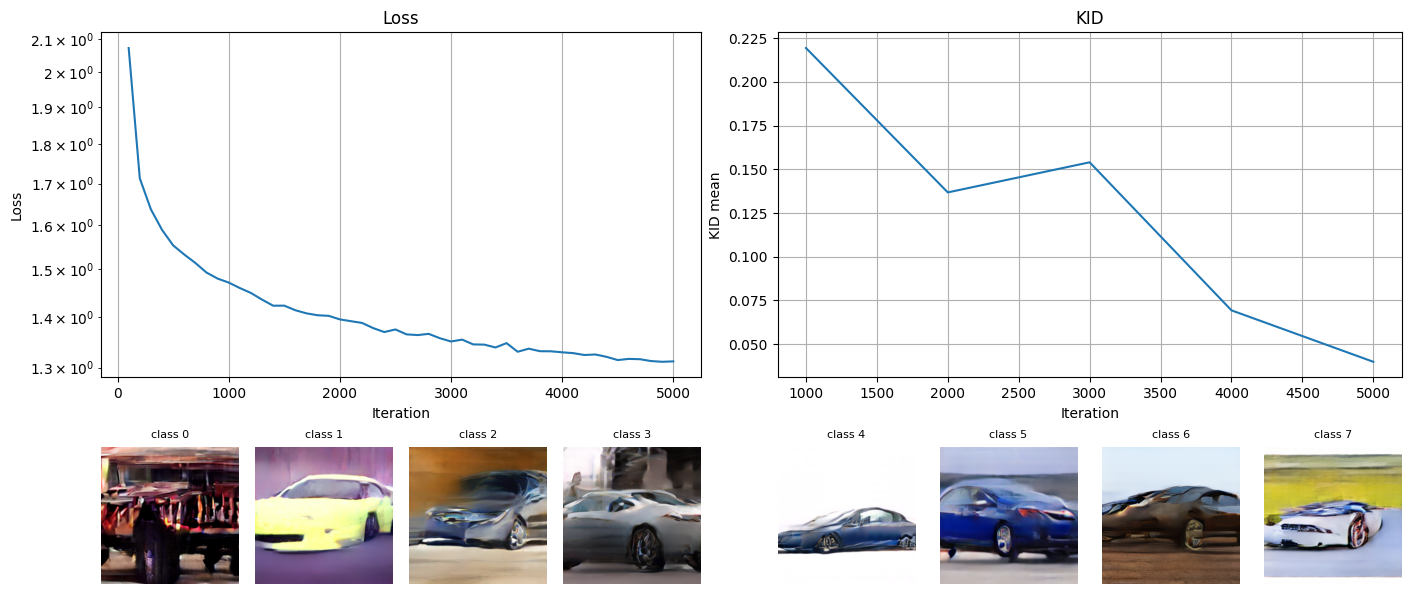

In [13]:
# Consider less iteration for debugging

train_model(
    model,
    optimizer,
    5000,
    vae=vae,
    dino_encoder=dino_encoder,
    repa=repa,
    extractor=extractor,
)

## Conclusions

Please discuss the design choices and techniques that led to noticeable improvements (faster convergence or better overall results). Discuss difficultes you faced during the task.

**YOUR CONCLUSIONS**